# IMPORTS

In [4]:
import numpy as np
import os, sys, importlib, json
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
import csv

# utils path
sys.path.append(os.path.abspath(os.path.join("..")))

# helper modules -  reload in case of edits
import utils.eda_helpers as eda_helpers
import utils.helpers as helpers
import utils.eda_plots as eda_plots
importlib.reload(eda_helpers)
importlib.reload(helpers)
importlib.reload(eda_plots)
from utils.eda_helpers import *
from utils.helpers import convert_to_serializable, save_json, load_csv_data_streamed
from utils.eda_plots import *

ImportError: cannot import name 'count_missing_unavailable' from 'utils.eda_helpers' (c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\utils\eda_helpers.py)

In [ ]:
# Random seed
np.random.seed(42)

# Setup save directory (always points to repo root)
repo_root = os.path.abspath(os.path.join(".."))

save_dir = os.path.join(repo_root, "results", "eda")
os.makedirs(save_dir, exist_ok=True)
print(f"All outputs will be saved under: {save_dir}")

plots_dir = os.path.join(repo_root, "plots", "eda")
os.makedirs(plots_dir, exist_ok=True)
print(f"All plots will be saved under: {plots_dir}")

All outputs will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda
All plots will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda


In [ ]:
# load the dataset
# x_train, x_test, y_train, train_ids, test_ids = load_csv_data("../dataset/")
x_train, x_test, y_train, train_ids, test_ids = load_csv_data_streamed("../dataset/")

# check shape
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)

x_train shape: (328135, 321)
y_train shape: (328135,)
x_test shape: (109379, 321)


# 1. Basic EDA

### Size dataset

In [4]:
n, d = x_train.shape
print("Number of samples:", n)
print("Number of features:", d)
print("\ny distribution:", np.unique(y_train, return_counts=True))
print("Estimated memory (MB):", x_train.nbytes/1e6)
print("Data type:", x_train.dtype)

Number of samples: 328135
Number of features: 321

y distribution: (array([-1,  1]), array([299160,  28975]))
Estimated memory (MB): 421.32534
Data type: float32


### Features descriptive statistics

In [5]:
with open(os.path.join("..", "dataset", "x_train.csv"), "r") as f:
    reader = csv.reader(f)
    header = next(reader)  # first line = column names
feature_names = header[1:]  # exclude ID column
feature_names[:20]

['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENUM',
 'PVTRESD1',
 'COLGHOUS',
 'STATERES',
 'CELLFON3',
 'LADULT',
 'NUMADULT',
 'NUMMEN',
 'NUMWOMEN',
 'CTELNUM1',
 'CELLFON2']

In [6]:
summary_extended = dataset_describe(
    x_train,
    feature_names=feature_names,
    y=y_train,
    max_features=20,
    save_dir=save_dir,
    save_name="dataset_summary_extended",
    extended=True
)


Dataset shape: 328,135 samples × 321 features
 Idx |            Name |    dtype |   Unique |   Miss |   %Miss |       Mean |        Std |        Min |        Max
-------------------------------------------------------------------------------------------------------------------
   0 | _STATE          |    float |       53 |      0 |    0.00 |         30 |         16 |          1 |         72
   1 | FMONTH          |    float |       12 |      0 |    0.00 |       6.36 |       3.49 |          1 |         12
   2 | IDATE           |    float |      414 |      0 |    0.00 |   6.56e+06 |   3.49e+06 |   1.01e+06 |   1.23e+07
   3 | IMONTH          |    float |       12 |      0 |    0.00 |       6.42 |       3.49 |          1 |         12
   4 | IDAY            |    float |       31 |      0 |    0.00 |       14.5 |       8.33 |          1 |         31
   5 | IYEAR           |    float |        2 |      0 |    0.00 |   2.02e+03 |      0.155 |   2.02e+03 |   2.02e+03
   6 | DISPCODE        | 

In [7]:
# print extended summary
for f in summary_extended[:1]:
    print(f"\nFeature {f['index']}: {f['name']}")
    for k, v in f.items():
        if k not in ['index', 'name']:
            print(f"  {k}: {v}")


Feature 0: _STATE
  dtype: float32
  type_inferred: float
  n_unique: 53
  unique_values_sample: [1.0, 2.0, 4.0, 5.0, 6.0]
  missing_count: 0
  missing_pct: 0.0
  mean: 29.973651885986328
  std: 16.03175163269043
  min: 1.0
  max: 72.0
  variance: 257.01708984375
  has_coded_missing: True
  skewness: 0.1320333480834961
  kurtosis: -0.7331421375274658
  entropy: 0.8267088644507566
  outlier_pct: 0.0
  corr_with_target: 0.005628057924762388


### Missing values

In [8]:
n = x_train.shape[0]
missing_per_feature = np.isnan(x_train).sum(axis=0)
missing_ratio = missing_per_feature / n * 100

In [9]:
# global summary ab missing values
missing_summary = {
    "total_missing": int(np.isnan(x_train).sum()),
    "mean_missing_pct": float(np.mean(missing_ratio)),
    "median_missing_pct": float(np.median(missing_ratio)),
    "max_missing_pct": float(np.max(missing_ratio)),
    "n_features_missing": int(np.sum(missing_per_feature > 0)),
}
save_json(missing_summary, "missing_summary", save_dir=save_dir)

Saved missing_summary.json to c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\missing_summary.json


In [10]:
# per-feature summary
missing_features_summary = [
    {"index": i, "name": feature_names[i], "missing_count": int(missing_per_feature[i]), "missing_pct": float(missing_ratio[i])}
    for i in range(len(feature_names))
]
save_json(missing_features_summary, "missing_features_summary", save_dir=save_dir)

Saved missing_features_summary.json to c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\missing_features_summary.json


In [11]:
# print
print(f"\nTotal missing values: {missing_summary['total_missing']:,}")
print(f"Average missing per feature: {missing_summary['mean_missing_pct']:.3f}%")
print(f"Features with any missing values: {missing_summary['n_features_missing']} / {len(feature_names)}")
print(f"Max missing percentage: {missing_summary['max_missing_pct']:.2f}% ({feature_names[np.argmax(missing_ratio)]})")


Total missing values: 47,175,779
Average missing per feature: 44.788%
Features with any missing values: 239 / 321
Max missing percentage: 99.99% (COLGHOUS)


Saved plot: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\missing_values.png


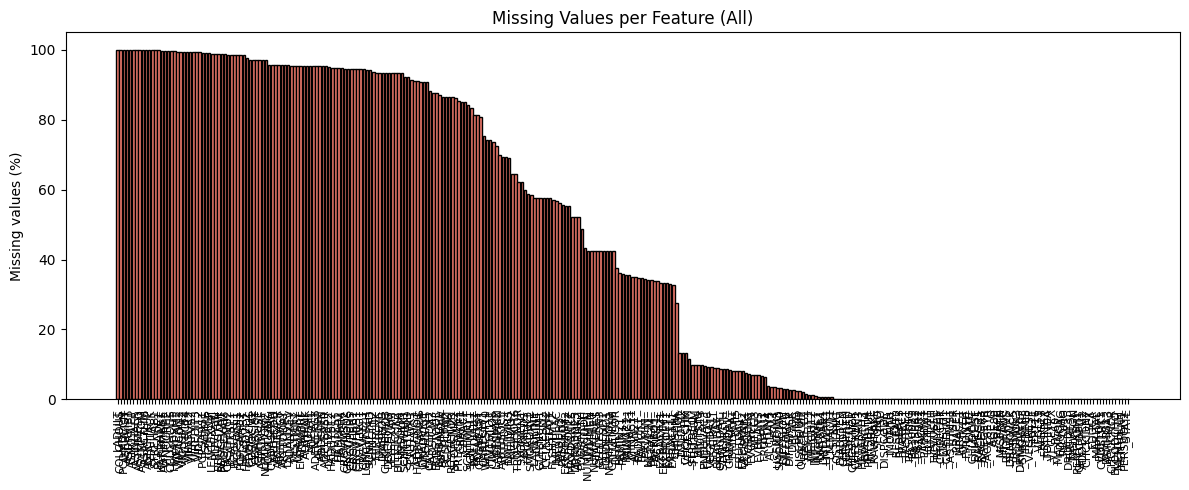

Saved plot: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\missing_unavailable.png


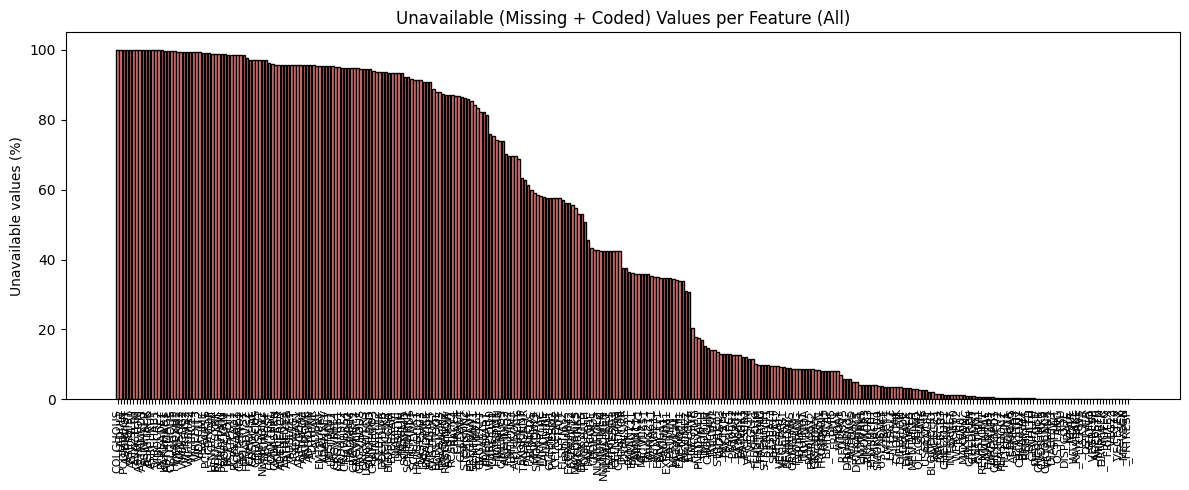

In [ ]:
# plot missing values (top 25)
plot_missing_values(
    x_train,
    feature_names=feature_names,
    top_n = None,
    save_dir=plots_dir,
    file_name="missing_values.png"
)

# plot unavailable (NaN + coded 7,9,77,99 etc) values
plot_missing_unavailable(
    x_train,
    feature_names=feature_names,
    top_n=None,
    save_dir=plots_dir,
    file_name="missing_unavailable.png"
)

In [13]:
# identify highly unavailable features (>90%)
unavailable_counts = count_missing_unavailable(x_train)
unavailable_ratio = 100 * unavailable_counts / n
high_unavailable_idx = np.where(unavailable_ratio > 90)[0]

if len(high_unavailable_idx) > 0:
    print(f"\nFeatures with >90% unavailable values:")
    for i in high_unavailable_idx:
        print(f"  {feature_names[i]} — {unavailable_ratio[i]:.2f}%")
    
    high_unavailable_summary = [
        {"index": int(i),
         "name": feature_names[i],
         "unavailable_pct": float(unavailable_ratio[i])}
        for i in high_unavailable_idx
    ]
    save_json(high_unavailable_summary, "high_unavailable_features", save_dir=save_dir)
else:
    print("\nNo features with >90% unavailable values found.")



Features with >90% unavailable values:
  COLGHOUS — 99.99%
  LADULT — 99.99%
  CCLGHOUS — 99.76%
  NUMPHON2 — 97.05%
  LASTSMK2 — 90.89%
  INSULIN — 93.39%
  BLDSUGAR — 93.50%
  FEETCHK2 — 93.58%
  DOCTDIAB — 93.65%
  CHKHEMO3 — 93.83%
  FEETCHK — 93.67%
  EYEEXAM — 93.49%
  DIABEYE — 93.47%
  DIABEDU — 93.41%
  CRGVREL1 — 95.17%
  CRGVLNG1 — 94.65%
  CRGVHRS1 — 94.90%
  CRGVPRB1 — 95.14%
  CRGVPERS — 94.63%
  CRGVHOUS — 94.63%
  CRGVMST2 — 94.78%
  VIDFCLT2 — 99.28%
  VIREDIF3 — 99.28%
  VIPRFVS2 — 99.29%
  VINOCRE2 — 99.82%
  VIEYEXM2 — 99.45%
  VIINSUR2 — 99.30%
  VICTRCT4 — 99.28%
  VIGLUMA2 — 99.28%
  VIMACDG2 — 99.29%
  CDHOUSE — 97.13%
  CDASSIST — 97.09%
  CDHELP — 99.07%
  CDSOCIAL — 97.12%
  CDDISCUS — 97.10%
  WTCHSALT — 90.72%
  LONGWTCH — 94.58%
  DRADVISE — 90.73%
  ASTHMAGE — 99.76%
  ASATTACK — 99.85%
  ASERVIST — 99.93%
  ASDRVIST — 99.93%
  ASRCHKUP — 99.85%
  ASACTLIM — 99.86%
  ASYMPTOM — 99.86%
  ASNOSLEP — 99.90%
  ASTHMED3 — 99.86%
  ASINHALR — 99.85%
  HAREHAB1

### Feature distribution analysis

In [14]:
stds = np.nanstd(x_train, axis=0)
means = np.nanmean(x_train, axis=0)
skews = np.array([feature_skewness(x_train[:, i]) for i in range(x_train.shape[1])])
kurtoses = np.array([feature_kurtosis(x_train[:, i]) for i in range(x_train.shape[1])])

print(f"Avg std across features: {np.mean(stds):.3f}")
print(f"Features with high skewness (|skew| > 2): {(np.abs(skews) > 2).sum()}")
print(f"Features with heavy tails (kurtosis > 3): {(kurtoses > 3).sum()}")

Avg std across features: 23288.543
Features with high skewness (|skew| > 2): 196
Features with heavy tails (kurtosis > 3): 209


In [15]:
plot_feature_distribution(x_train, feature_names, idx=0, plot = False)
plot_feature_distribution(x_train, feature_names, idx=18, y=y_train, plot = False)

In [ ]:
# histogram subdirectories
hist_dir_single = os.path.join(plots_dir, "histograms", "single-features")
hist_dir_target = os.path.join(plots_dir, "histograms", "target-feature")

os.makedirs(hist_dir_single, exist_ok=True)
os.makedirs(hist_dir_target, exist_ok=True)

print(f"Histograms (single features): {hist_dir_single}")
print(f"Histograms (feature vs target): {hist_dir_target}")

Histograms (single features): c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\histograms\single-features
Histograms (feature vs target): c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\histograms\target-feature


In [23]:
d = len(feature_names)

# # save feature histograms
# for i in range(d):  
#     plot_feature_distribution(
#         x_train,
#         feature_names,
#         idx=i,
#         save_dir=hist_dir_single,
#         file_name=f"{feature_names[i]}_hist.png",
#         plot = False
#     )
#     print(f"Saved {i}/{d} plots.")

In [24]:
# # save feature-target histograms
# for i in range(d): 
#     plot_feature_distribution(
#         x_train,
#         feature_names,
#         idx=i,
#         y=y_train,
#         save_dir=hist_dir_target,
#         file_name=f"{feature_names[i]}_hist_by_target.png",
#         plot = False
#     )
#     print(f"Saved {i}/{d} plots.")

### Target distribution (class balance)

Target distribution summary:
----------------------------------------
Class  -1:   299160 samples (91.17%)
Class   1:    28975 samples ( 8.83%)
----------------------------------------
Total samples: 328135



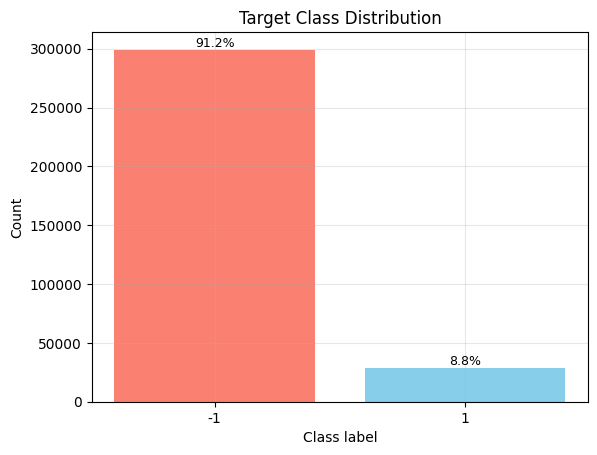

Saved target_summary.json to c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\target_summary.json


In [ ]:
classes, counts = np.unique(y_train, return_counts=True)
total = np.sum(counts)
percentages = counts / total * 100

print("Target distribution summary:")
print("-" * 40)
for c, n, p in zip(classes, counts, percentages):
    print(f"Class {int(c):>3}: {n:>8} samples ({p:5.2f}%)")
print("-" * 40)
print(f"Total samples: {total}\n")

# plot class balance
plt.bar(classes.astype(str), counts, color=["salmon", "skyblue"])
plt.title("Target Class Distribution")
plt.xlabel("Class label")
plt.ylabel("Count")
for i, (n, p) in enumerate(zip(counts, percentages)):
    plt.text(i, n, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

# save
target_summary = {
    "total_samples": int(total),
    "class_counts": {int(c): int(n) for c, n in zip(classes, counts)},
    "class_percentages": {int(c): float(p) for c, p in zip(classes, percentages)},
}
save_json(target_summary, "target_summary")

# 2. Univariate statistics

### Histograms + KDE

In [ ]:
# histogram subdirectories
hist_dir_single = os.path.join(plots_dir, "histograms", "single-features")
hist_dir_target = os.path.join(plots_dir, "histograms", "target-feature")

os.makedirs(hist_dir_single, exist_ok=True)
os.makedirs(hist_dir_target, exist_ok=True)

print(f"Histograms (single features): {hist_dir_single}")
print(f"Histograms (feature vs target): {hist_dir_target}")

In [ ]:
# for i in range(d):
#     plot_feature_kde_distribution(
#         x_train, feature_names, idx=i,
#         save_dir=hist_dir_single,
#         file_name=f"{feature_names[i]}_hist_kde.png",
#         plot=False
#     )
#     print(f"Saved {i}/{d} plots")

In [ ]:
# for i in range(d):
#     plot_feature_kde_distribution(
#         x_train, feature_names, idx=i,
#         y=y_train,
#         save_dir=hist_dir_target,
#         file_name=f"{feature_names[i]}_hist_kde_by_target.png",
#         plot=False
#     )
#     print(f"Saved {i}/{d} plots")

### Boxplots

In [ ]:
# boxplot subdirectories
box_dir_single = os.path.join(plots_dir, "boxplots", "single-features")
box_dir_target = os.path.join(plots_dir, "boxplots", "target-feature")

os.makedirs(box_dir_single, exist_ok=True)
os.makedirs(box_dir_target, exist_ok=True)

print(f"Boxplots (single features): {box_dir_single}")
print(f"Boxplots (feature vs target): {box_dir_target}")

Boxplots (single features): c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\boxplots\single-features
Boxplots (feature vs target): c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\boxplots\target-feature


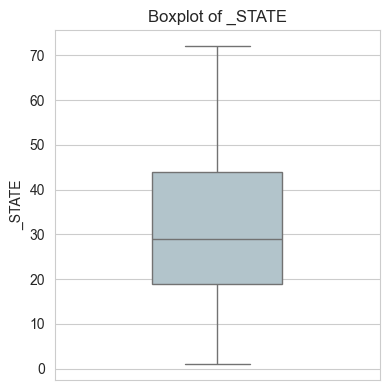

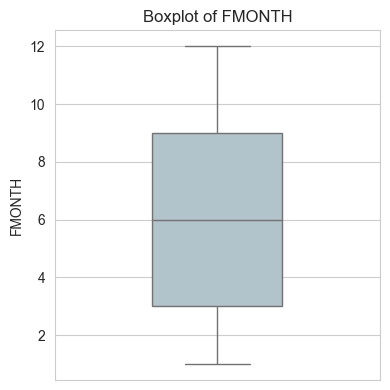

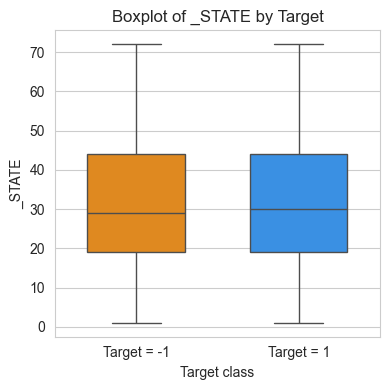

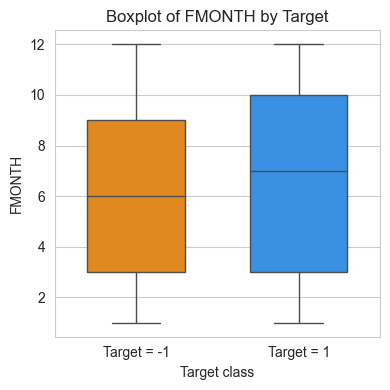

In [49]:
for i in range(2):
    plot_feature_boxplot(
        x_train, feature_names, idx=i,
        save_dir=box_dir_single,
        file_name=f"{feature_names[i]}_box.png",
        plot=True
    )

for i in range(2):
    plot_feature_boxplot(
        x_train, feature_names, idx=i,
        y=y_train,
        save_dir=box_dir_target,
        file_name=f"{feature_names[i]}_box_by_target.png",
        plot=True
    )

In [ ]:
# for i in range(d):
#     plot_feature_boxplot(
#         x_train, feature_names, idx=i,
#         save_dir=box_dir_single,
#         file_name=f"{feature_names[i]}_box.png",
#         plot=False
#     )
#     print(f"Saved {i}/{d} plots.")

In [ ]:
# for i in range(d):
#     plot_feature_boxplot(
#         x_train, feature_names, idx=i,
#         y=y_train,
#         save_dir=box_dir_target,
#         file_name=f"{feature_names[i]}_box_by_target.png",
#         plot=False
#     )
#     print(f"Saved {i}/{d} plots.")

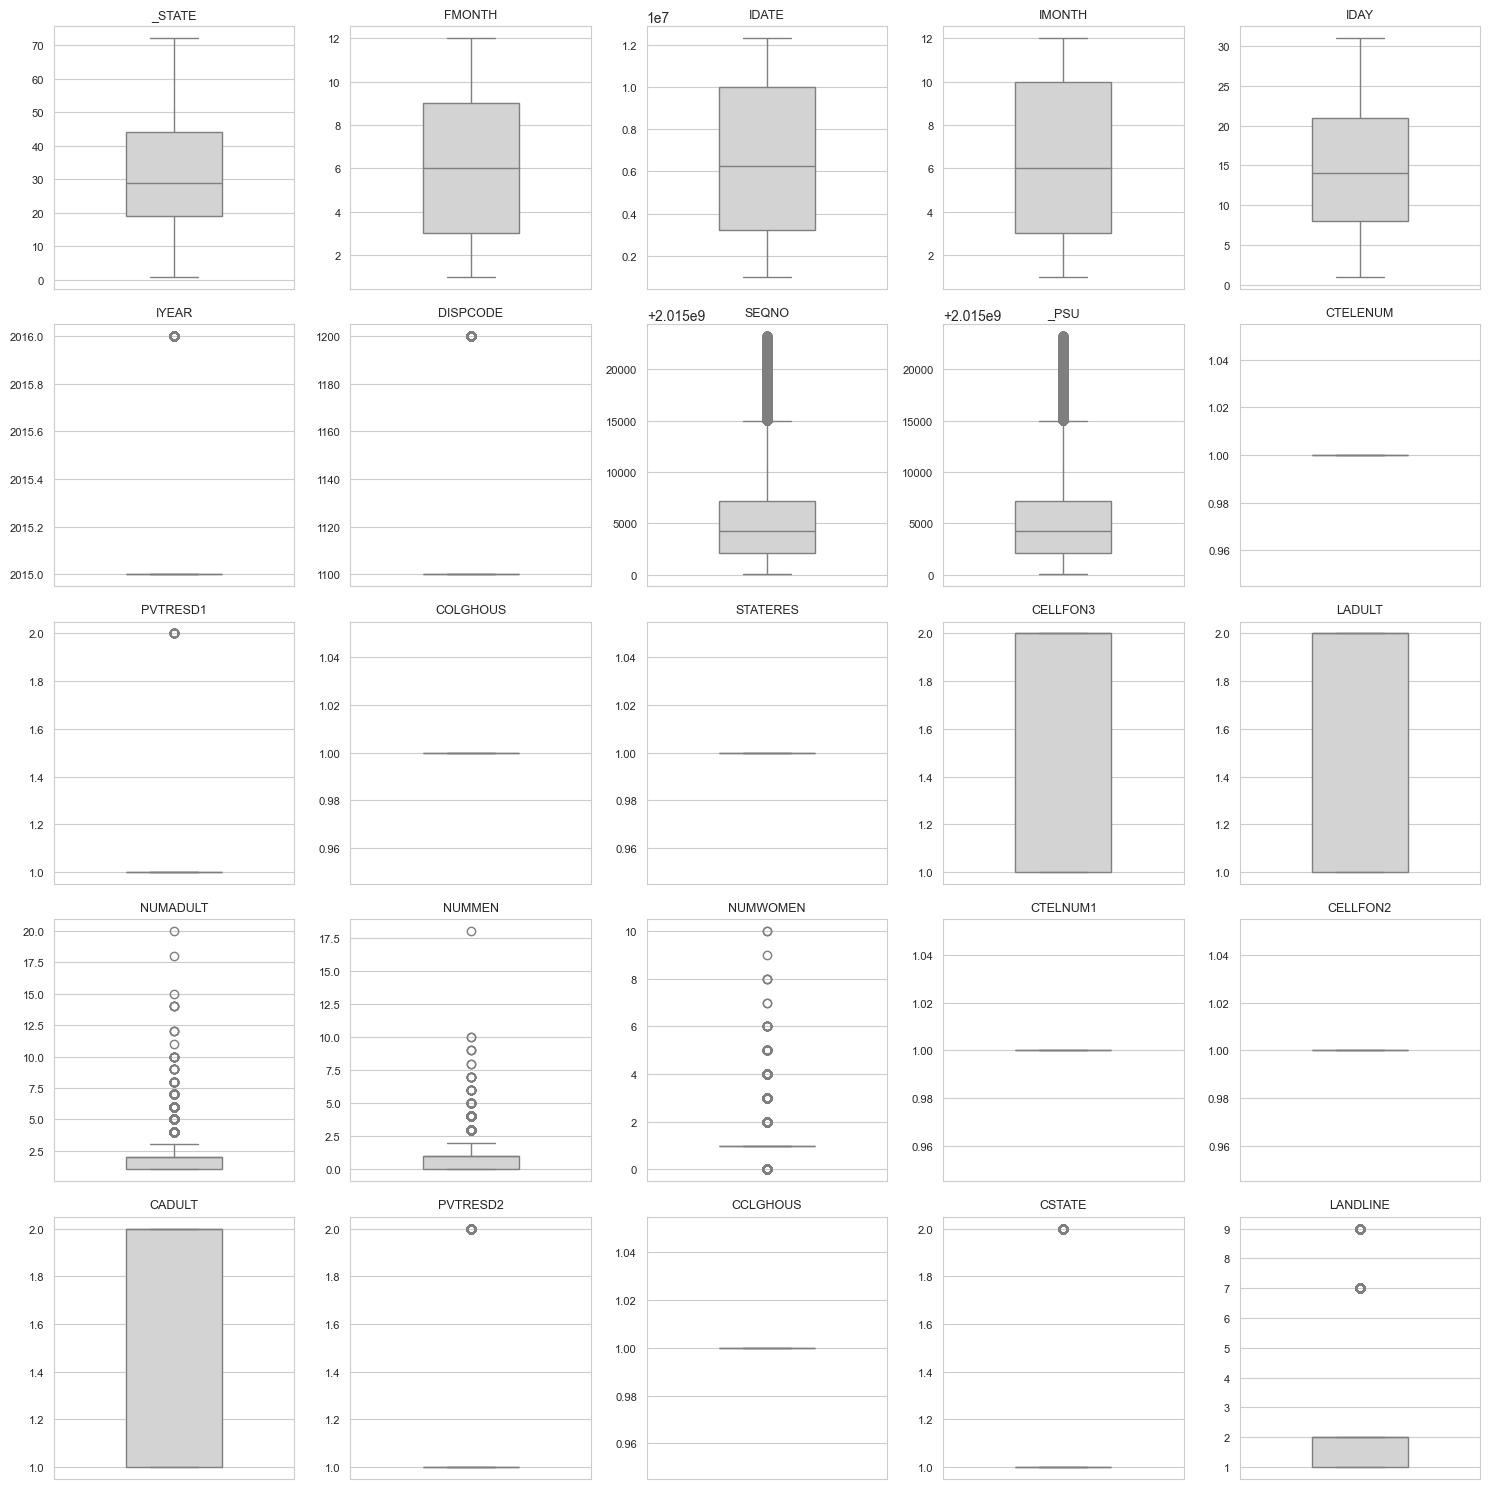

In [50]:
# batch-boxplots for features
n_rows, n_cols = 5, 5
n_features = x_train.shape[1]
n_total = n_rows * n_cols
indices = list(range(0,25))  # first 25 features

fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
axes = axes.flatten()

for i, idx in enumerate(indices):
    ax = axes[i]
    x = x_train[:, idx]
    valid_mask = ~np.isnan(x)
    x_valid = x[valid_mask]
    sns.boxplot(y=x_valid, ax=ax, color="lightgray", width=0.4)
    ax.set_title(feature_names[idx], fontsize=9)
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


C:\Users\emmaa\AppData\Local\Temp\ipykernel_22980\2369209289.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y="value", data=data, ax=ax,
C:\Users\emmaa\AppData\Local\Temp\ipykernel_22980\2369209289.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y="value", data=data, ax=ax,
C:\Users\emmaa\AppData\Local\Temp\ipykernel_22980\2369209289.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y="value", data=data, ax=ax,
C:\Users\emmaa\AppData\Local\Temp\ipykernel_22980\2369209289.py:19: FutureWarning:

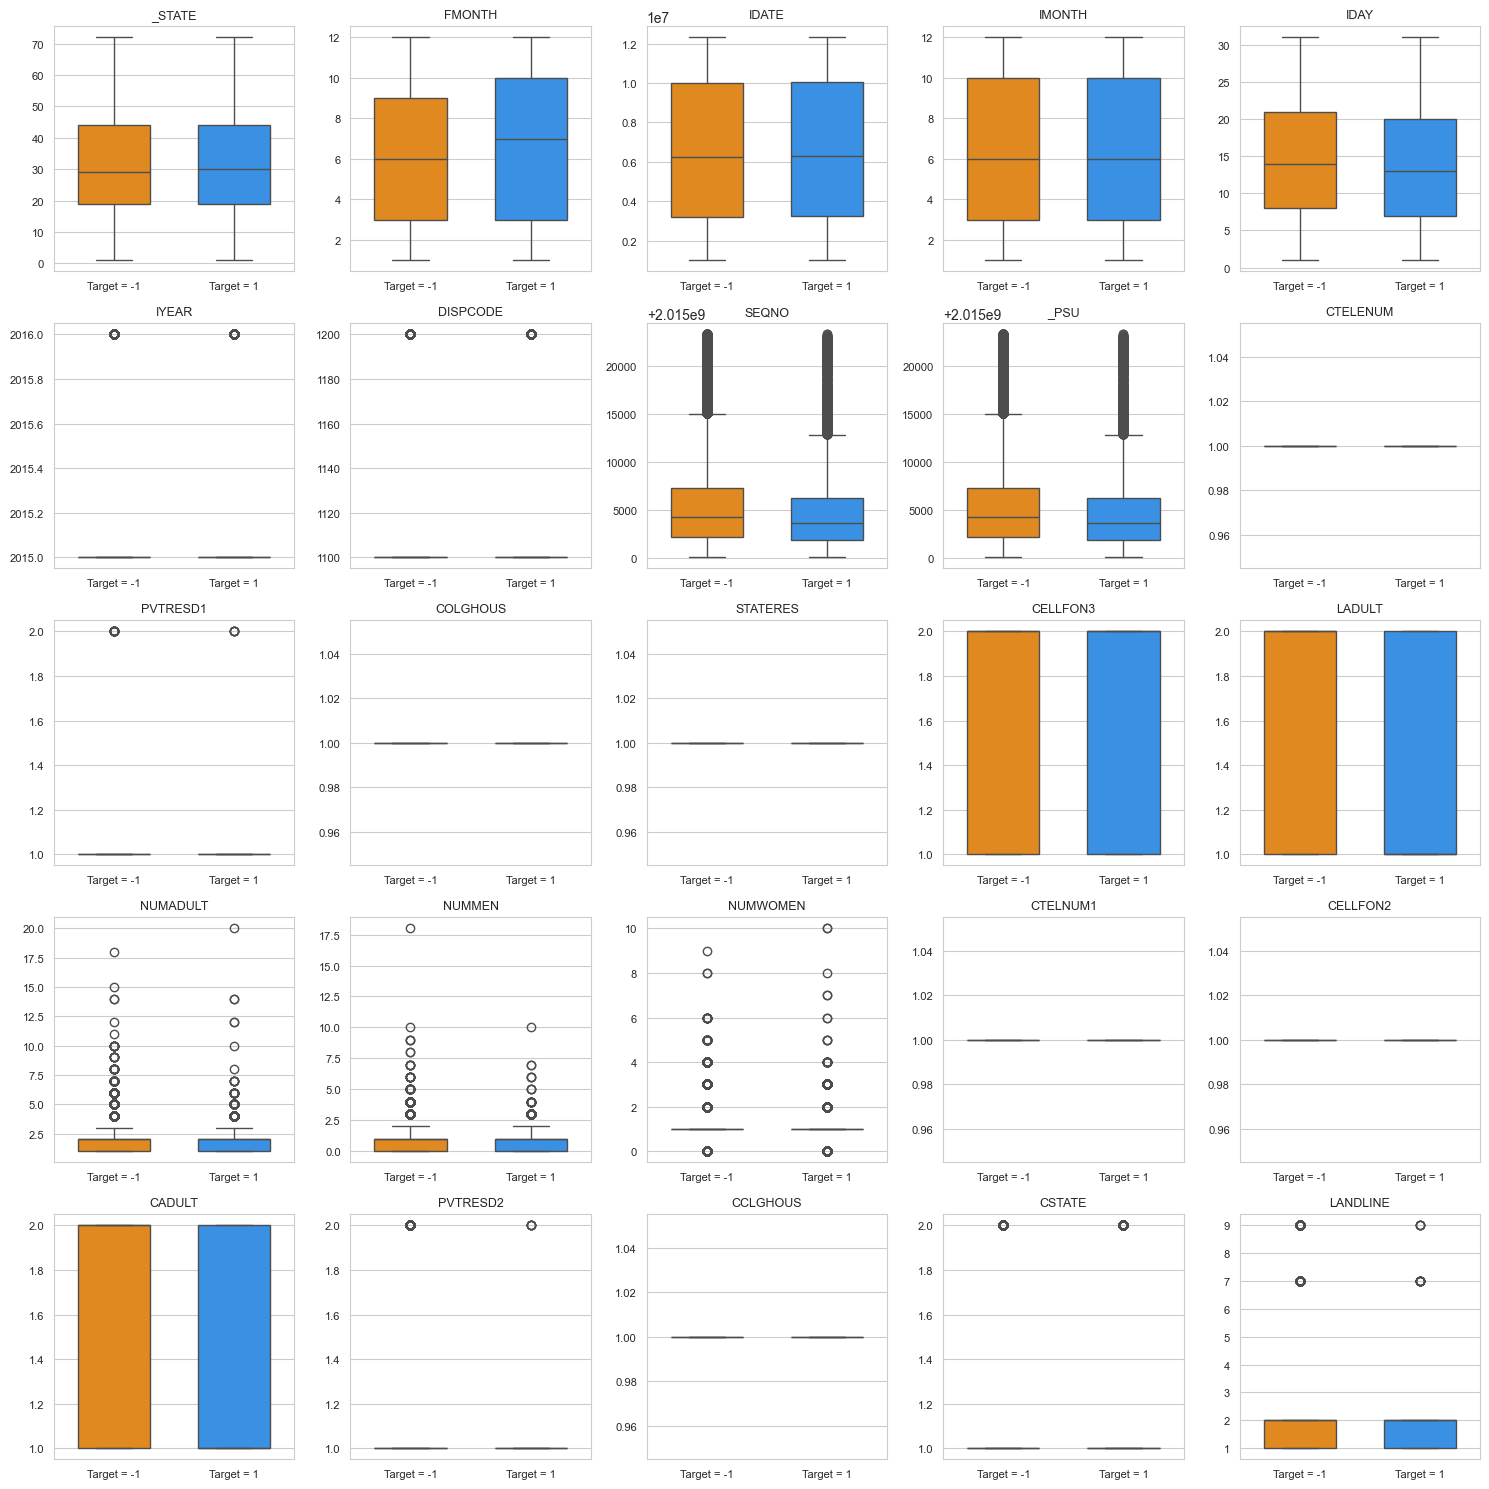

In [51]:
n_rows, n_cols = 5, 5
n_features = x_train.shape[1]
n_total = n_rows * n_cols
indices = list(range(0,25))  # first 25 features

fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
axes = axes.flatten()

for i, idx in enumerate(indices):
    ax = axes[i]
    x = x_train[:, idx]
    valid_mask = ~np.isnan(x)
    x_valid = x[valid_mask]
    y_valid = y_train[valid_mask]
    data = {
        "value": x_valid,
        "target": np.where(y_valid == 1, "Target = 1", "Target = -1")
    }
    sns.boxplot(x="target", y="value", data=data, ax=ax,
                palette={"Target = 1": "dodgerblue", "Target = -1": "darkorange"},
                width=0.6)
    ax.set_title(feature_names[idx], fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# 3. EDA on reduced feature set 

In [1]:
# reduced feature set (after removing high na, duplicates, not interesting etc)

reduced_feature_set = ['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTAE1', '_PASTRNG', 'EDUCA', '_RFHLTH', 'CHCCOPD1', 'DRADVISE', 
                        'CHCKIDNY', 'ARTHSOCL', 'SMOKDAY2', '_RFSEAT2', '_MISVEGN', 'WTCHSALT', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 
                        'DIABAGE2', 'VETERAN3', 'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_TOTINDA', '_PACAT1', 
                        'INSULIN', 'DROCDY3_', 'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'MAXDRNKS', '_LMTWRK1', 'RENTHOM1', 'PAMIN11_', 
                        'PADUR2_', 'STOPSMK2', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 'POORHLTH', 'FRUTDA1_', 'DIABETE3', '_FRUTSUM', '_LMTACT1',
                        'PERSDOC2', 'STRFREQ_', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 'DRNK3GE5', 'ALCDAY5', 'BPHIGH4', 'GENHLTH',
                        'EXRACT11', '_FRUITEX', '_BMI5', 'PAVIG11_', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'AVEDRNK2', 'ORNGDAY_', 
                        '_MISFRTN', 'MSCODE', 'PHYSHLTH', 'TOLDHI2', '_SMOKER3', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'WTKG3', 'CHCSCNCR', 
                        'PAFREQ1_', '_AIDTST3', 'FLSHTMY2', 'PA1VIGM_', 'HIVTST6', 'METVL21_', '_PAINDX1', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 
                        'MAXVO2_', 'VEGEDA1_', '_RACE_G1', 'GRENDAY_', '_MINAC11', 'LONGWTCH', 'FC60_', 'PAMISS1_', 'SCNTWRK1', 'FEETCHK2', 
                        'EMPLOY1', 'BLOODCHO', 'USENOW3', 'PAMIN21_', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 'ADDEPEV2', '_AGE80', 
                        'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', '_MINAC21', '_CRACE1', 'PREDIAB1', 'BPMEDS', '_VEGETEX', 
                        'HAVARTH3', 'PAVIG21_', 'CHECKUP1', 'TRNSGNDR', 'CHILDREN']